## Imports

In [1]:
import torch
import os
import torch.optim as optim
from collections import namedtuple, deque
from IPython import display
import gym
import random
import time
import math
from gym import Env, spaces
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import cv2
import math
import random
import matplotlib
import matplotlib.pyplot as plt
from collections import namedtuple, deque
from itertools import count
from stable_baselines3 import PPO, A2C, SAC
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.evaluation import evaluate_policy
from torchsummary import summary
import sys
from simple_ma_env_uav import Simple_MA_Env_Centralized_UAV
from simple_ma_env_ugv import Simple_MA_Env_Centralized_UGV
from simple_ma_env_uav_ugv import Simple_MA_Env_Centralized_UAV_UGV
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random
from collections import deque
import gym
import torchvision.transforms as T
import gymnasium as gym
import matplotlib.pyplot as plt
import torch
import copy
import random
from collections import deque
from PIL import Image

/Users/shahmirkhan/miniconda3/envs/torch-gpu/lib/python3.8/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: 'dlopen(/Users/shahmirkhan/miniconda3/envs/torch-gpu/lib/python3.8/site-packages/torchvision/image.so, 0x0006): Symbol not found: __ZN3c1017RegisterOperatorsD1Ev
  Referenced from: <AA076682-B999-31A8-AEA6-2BF697B54762> /Users/shahmirkhan/miniconda3/envs/torch-gpu/lib/python3.8/site-packages/torchvision/image.so
  Expected in:     <AEDB2D9B-AE02-3964-90EC-49E2AD5A10A1> /Users/shahmirkhan/miniconda3/envs/torch-gpu/lib/python3.8/site-packages/torch/lib/libtorch_cpu.dylib'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(


## Defining the device type and environment

In [2]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
if device.type == "mps": print("Using GPU")
else: print("Using CPU")

## Initialize the env
env = Simple_MA_Env_Centralized_UAV(100)
env1 = Simple_MA_Env_Centralized_UGV(100)

Using GPU


In [3]:
## This class include functions such as action selection using epsilon greedy, training step update
class DQNAgent:
    def __init__(self, epsilon_decay, initial_epsilon, final_epsilon, discount_factor, action_value_function, loss_fn, optimizer, device):
        self.epsilon_decay = epsilon_decay
        self.initial_epsilon = initial_epsilon
        self.final_epsilon = final_epsilon
        self.discount_factor = discount_factor
        self.action_value_function = action_value_function
        self.target_action_value_function = copy.deepcopy(action_value_function).to(device)
        self.loss_fn = loss_fn
        self.optimizer = optimizer
        self.epsilon = 1
        self.training_step_counter = 0
        self.action_counter = 0
        self.previous_action = None
        self.device=device
        
        
    def select_action(self, action_space, current_state):
        possible_actions = list(range(action_space))
        if self.action_counter % 4 == 0 or self.previous_action == None:
            if random.random() < self.epsilon:
                    chosen_action = random.choice(possible_actions)
            else:
                with torch.no_grad():
                    q_values = self.action_value_function(current_state)
                    chosen_action = torch.argmax(q_values).item()
            self.previous_action = chosen_action
        else:
            chosen_action = self.previous_action
        
        self.action_counter += 1
        return chosen_action
    
    def update_action_value_function(self, new_action_value_function):
        self.action_value_function = new_action_value_function

    def update_target_action_value_function(self):
        self.target_action_value_function = copy.deepcopy(self.action_value_function).to(self.device)

    def training_step(self, minibatch):
        batch_states, batch_actions, batch_rewards, batch_next_states, batch_terminated = zip(*minibatch)
        batch_states = torch.stack(batch_states).to(self.device)
        batch_actions = torch.tensor(batch_actions, dtype=torch.long, device=self.device) #.to(self.device)
        batch_rewards = torch.tensor(batch_rewards, device=self.device) #.to(self.device)
        batch_next_states= torch.stack(batch_next_states).to(self.device)
        batch_terminated = torch.tensor(batch_terminated, device=self.device) #.to(self.device)
        q_values = self.action_value_function(batch_states)
        #current_q = self.action_value_function(batch_states)[batch_actions]
        batch_actions = batch_actions.unsqueeze(1).to(q_values.device)
        current_q = q_values.gather(1, batch_actions).squeeze(1)
        batch_total = current_q

        not_done_mask = ~ (batch_terminated)
        next_q_values = self.target_action_value_function(batch_next_states).detach()
        next_q_max, _ = torch.max(next_q_values, dim=1)
        batch_target = batch_rewards + self.discount_factor * next_q_max * not_done_mask
        loss = self.loss_fn(batch_total, batch_target)

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        if self.training_step_counter >= 10000:
            self.target_action_value_function = copy.deepcopy(self.action_value_function).to(self.device)
            self.training_step_counter = 0
        self.training_step_counter += 1

    def decrement_epsilon(self):
        self.epsilon = max(self.final_epsilon, self.epsilon - self.epsilon_decay)

    def get_epsilon(self):
        return self.epsilon
    
    def get_final_model(self):
        return self.action_value_function

In [4]:
## This is the model whose weights are shared among different agents. Every weight is shared except fc2 -> output.
class Model(nn.Module):
    def __init__(self, num_actions):
        super(Model, self).__init__()
        self.conv1 = nn.Conv2d(4, 32, kernel_size=8, stride=4) #32 filters of 8x8 with stride 4. ReLU Activation
        self.conv2 = nn.Conv2d(32, 64, kernel_size=4, stride=2) #64 filters of 4x4 with stride 2. ReLU Activation
        self.conv3 = nn.Conv2d(64, 64, kernel_size=3, stride=1) #64 filters of 3x3 stride 1. Followed by ReLU Activation
        self.fc1 = nn.Linear(256, 128) 
        self.fc2 = nn.Linear(128, num_actions)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))

        return self.fc2(x)

In [5]:
class ReplayBuffer:
    def __init__(self, buffer_size):
        self.data = deque()
        self.buffer_size = buffer_size

    def insert_data(self, state, action, reward, next_state, terminated):
        self.data.append((state, action, reward, next_state, terminated))

    def sample_data(self, num_of_data):
        return random.sample(self.data, min(len(self.data), num_of_data))
    
    def update_replay_buffer(self):
        if len(self.data) > self.buffer_size:
            self.data.popleft()
    
    def get_length(self):
        return len(self.data)

In [6]:
def rgb2gray(rgb):
    return np.dot(rgb[...,:3], [0.2989, 0.5870, 0.1140])

## Downscale the snapshot of the state to later stack as 4 frames
def downscale_image(image, target_size=(50, 50)):
    resized_image = cv2.resize(image, target_size)
    resized_image = np.array(resized_image)
    resized_image = rgb2gray(resized_image)
    return resized_image


## Create frame stack of 4 previous states
def update_frame_stack(stack, new_frame):
    new_stack = torch.empty_like(stack)  # Create an empty tensor with the same shape and device as stack
    new_stack[0, :, :] = new_frame       # Insert the new frame at the beginning of the stack
    new_stack[1:, :, :] = stack[:-1, :, :]  # Shift the rest of the frames

    return new_stack

## Training UGV end-to-end

In [7]:
ugv_action_size = 4
action_value_function = Model(num_actions=ugv_action_size).to(device)
optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=0.00025, momentum=0.95)

In [8]:
episode_scores_runs = []
average_scores_runs = []

for r in range(5):
    env = Simple_MA_Env_Centralized_UGV(100)
    ugv_action_size = 4
    action_value_function = Model(num_actions=ugv_action_size).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=0.00025, momentum=0.95)
    observation = env.reset()
    LEARNING_RATE = 0.00025
    NUM_OF_STACKED_FRAMES = 4
    TRAINING_THRESHOLD = 50000
    EPSILON_DECAY = 0.0012
    INITIAL_EPSILON = 1
    FINAL_EPSILON = 0.1
    DISCOUNT_FACTOR = 0.99
    NUM_OF_STEPS_TO_UPDATE = 10000

    action_value_function = Model(num_actions=env.action_space.n).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
    deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
    replay_buffer = ReplayBuffer(50000)
    number_of_episodes = 1000
    step_counter = 0
    episode_scores = []
    for ep in range(1, number_of_episodes+1):
        state = env.reset()
        terminated = False
        episode_score = 0
        current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)

        while not terminated:
            previous_state = current_state

            action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

            observation, reward, terminated, info = env.step(action)
            # env.render()
            episode_score += reward
            reward = max(-1, min(reward, 1))

            downsized_observation = downscale_image(observation)
            downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

            current_state = update_frame_stack(current_state, downsized_observation_tensor)

            replay_buffer.insert_data(previous_state, action, reward, current_state, terminated)
            replay_buffer.update_replay_buffer()
    
            batch_data = replay_buffer.sample_data(32)


            if replay_buffer.get_length() >= TRAINING_THRESHOLD:
                deep_q_agent.training_step(batch_data)
                del batch_data

        torch.mps.empty_cache()

        deep_q_agent.decrement_epsilon()
        episode_scores.append(episode_score)
        #print(f"Episode {ep} has ended. Agent has scored {episode_score} for this episode")
        #print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")
    episode_scores_runs.append(episode_scores)


    average_scores = []
    chunk_size = 100

    for i in range(0, len(episode_scores), chunk_size):
        chunk = episode_scores[i:i + chunk_size]
        average_score = sum(chunk) / len(chunk)
        average_scores.append(average_score)
    average_scores_runs.append(average_scores)
    print(f"Run #{r} complete!")

# final_model = deep_q_agent.get_final_model()
# torch.save(final_model, 'trained_ugv_agent.pth')

# # Plotting the average scores
# plt.plot(average_scores)
# plt.title("Average Scores per 100 Episodes")
# plt.xlabel("Chunk of 100 Episodes")
# plt.ylabel("Average Score")
# plt.show()


# env.close()

Run #0 complete!
Run #1 complete!
Run #2 complete!
Run #3 complete!
Run #4 complete!


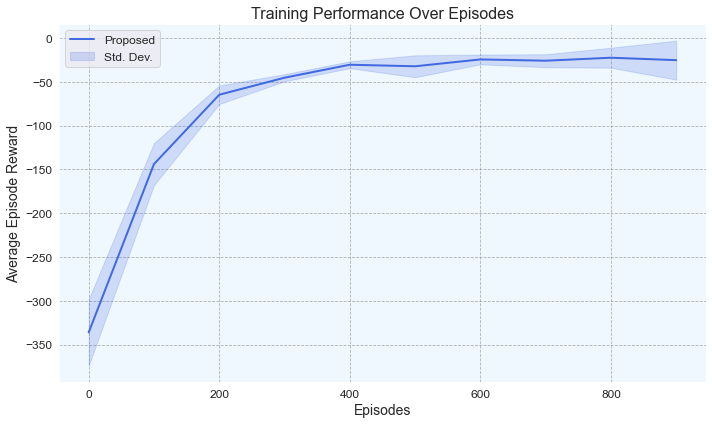

In [8]:
import seaborn as sns

rewards = np.array(average_scores_runs)
mean = rewards.mean(axis=0)
std = rewards.std(axis=0)

# Smoothing
# window = 5
# kernel = np.ones(window) / window
# mean_smooth = np.convolve(mean, kernel, mode='same')
# std_smooth = np.convolve(std, kernel, mode='same')

# Set seaborn style
#sns.set(style="whitegrid")
sns.set_style("dark")

# Episodes
episodes = list(range(0, 1000, 100))

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor('#ffffff')  # Change overall background color
ax.set_facecolor('#f0f8ff')         # Change inner plot background

# Plot lines
ax.plot(episodes, mean, color='royalblue', label='Proposed', linewidth=2)
ax.fill_between(episodes, mean - std, mean + std, 
                color='royalblue', alpha=0.2, label='Std. Dev.')

# Aesthetics
ax.set_xlabel('Episodes', fontsize=14)
ax.set_ylabel('Average Episode Reward', fontsize=14)
ax.set_title('Training Performance Over Episodes', fontsize=16)
ax.tick_params(axis='both', labelsize=12)
ax.grid(True, linestyle='--', alpha=0.6, color='gray')
ax.legend(fontsize=12)
plt.tight_layout()
plt.show()

In [10]:
average_scores_runs_dist = average_scores_runs.copy()
%store average_scores_runs_dist

Stored 'average_scores_runs_dist' (list)


In [22]:
episode_scores

[-89.90000000000006,
 -1609.2000000000107,
 -347.69999999999976,
 -9.300000000000002,
 -152.30000000000013,
 -49.09999999999997,
 -15.99999999999999,
 -14.5,
 3.2,
 -948.3999999999951,
 -1067.1999999999973,
 3.6,
 -4.9,
 -67.80000000000007,
 -859.1999999999971,
 -391.5999999999997,
 -73.39999999999999,
 -218.00000000000026,
 -0.2999999999999994,
 -1021.399999999996,
 -613.5999999999979,
 -719.7999999999967,
 -4.200000000000002,
 -387.29999999999956,
 -803.2999999999968,
 -149.80000000000013,
 -922.6999999999963,
 3,
 -446.699999999999,
 -80.60000000000002,
 3,
 -51.89999999999997,
 -219.10000000000022,
 -8.9,
 -1065.1999999999975,
 -51.69999999999998,
 -524.6999999999982,
 -268.30000000000007,
 -529.4999999999985,
 -10.400000000000006,
 -493.6999999999982,
 -210.8000000000002,
 -708.7999999999975,
 -994.7999999999956,
 -527.9999999999986,
 -166.80000000000013,
 -457.3999999999994,
 -75.90000000000003,
 -63.39999999999996,
 3,
 3,
 -891.0999999999958,
 -18.39999999999999,
 -24.499999999

## Load the trained UAV and UGV models and Test them

In [13]:
uav_model = torch.load('trained_uav_agent.pth')
ugv_model = torch.load('trained_ugv_agent_distributed.pth')
lap_regions_uav = []
lap_regions_ugv = []
all_steps = []
for i in range(500):
    env = Simple_MA_Env_Centralized_UAV_UGV(100)
    obs = env.reset()
    current_state = torch.zeros((4, 50, 50), dtype=torch.float32, device=device)
    done = False
    step = 0
    while not done:
        step += 1
        if random.random()>0.2:
            uav_action = torch.argmax(uav_model(current_state.unsqueeze(0))).item()
            ugv_action = torch.argmax(ugv_model(current_state.unsqueeze(0))).item()
        else: 
            uav_action = env.action_space_uav.sample()
            ugv_action = env.action_space_ugv.sample()

        obs,_,_,done,_,lap_region_uav, lap_region_ugv, steps = env.step(uav_action, ugv_action)
        # env.render()
        if step == 100:
            print("Time Out")
            done = True

        downsized_observation = downscale_image(obs)
        downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

        current_state = update_frame_stack(current_state, downsized_observation_tensor)
        # print(uav_action, ugv_action)
        # uav_action = env.action_space_uav.sample()
        # ugv_action = env.action_space_ugv.sample()
    all_steps.append(steps)
    lap_regions_uav.append(lap_region_uav)
    lap_regions_ugv.append(lap_region_ugv)
env.close()

<ipython-input-13-e9cc083b36b3>:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  uav_model = torch.load('trained_uav_agent.pth')
<ipython-input-13-e9cc083b36b3>:2: FutureWar

Time Out
Time Out
Time Out
Time Out
Time Out
Time Out
Time Out
Time Out


KeyboardInterrupt: 

In [12]:
## Average steps
summ = 0
for i in all_steps:
    summ += i
print("Average steps:",summ/(len(all_steps)))

Average steps: 20.81


In [7]:
## Test by starting UAV and UGV from the same location

uav_model = torch.load('trained_uav_agent.pth')
ugv_model = torch.load('trained_ugv_agent_distributed.pth')
lap_regions_uav = []
lap_regions_ugv = []

all_steps = []
for i in range(100):
    env = Simple_MA_Env_Centralized_UAV_UGV(100)
    obs = env.reset()
    x = random.randrange(int(env.observation_shape[0] * 0.2), int(env.observation_shape[0] * 0.8))
    y = random.randrange(int(env.observation_shape[1] * 0.2), int(env.observation_shape[1] * 0.8))
    env.agents['uav'].set_position(x,y)
    env.agents['ugv'].set_position(x,y)
    current_state = torch.zeros((4, 50, 50), dtype=torch.float32, device=device)
    done = False
    while not done:
        if random.random()>0.2:
            uav_action = torch.argmax(uav_model(current_state.unsqueeze(0))).item()
            ugv_action = torch.argmax(ugv_model(current_state.unsqueeze(0))).item()
        else: 
            uav_action = env.action_space_uav.sample()
            ugv_action = env.action_space_ugv.sample()

        obs,_,_,done,_,lap_region_uav, lap_region_ugv, steps = env.step(uav_action, ugv_action)
        # env.render()

        downsized_observation = downscale_image(obs)
        downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

        current_state = update_frame_stack(current_state, downsized_observation_tensor)
        # print(uav_action, ugv_action)
        # uav_action = env.action_space_uav.sample()
        # ugv_action = env.action_space_ugv.sample()
    all_steps.append(steps)
    lap_regions_uav.append(lap_region_uav)
    lap_regions_ugv.append(lap_region_ugv)
env.close()

<ipython-input-7-46c7b700f092>:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  uav_model = torch.load('trained_uav_agent.pth')
<ipython-input-7-46c7b700f092>:4: FutureWarni

In [8]:
## Unique Coverage Ratio (UCR)
UCR = 0
for i,j in zip(lap_regions_uav, lap_regions_ugv):  
    overlap = i * j
    union = i + j
    unique = np.count_nonzero(union) - np.count_nonzero(overlap)
    ucr = unique/np.count_nonzero(union)
    UCR += ucr
print(UCR/len(lap_regions_uav))

0.9264025967944555


In [9]:
## Trying Entropy of Visitation
sum_of_visitations_uav = lap_regions_uav[0] + lap_regions_uav[1]
for i in range(2,len(lap_regions_uav)):
    sum_of_visitations_uav += lap_regions_uav[i]

sum_of_visitations_ugv = lap_regions_ugv[0] + lap_regions_ugv[1]
for i in range(2,len(lap_regions_ugv)):
    sum_of_visitations_ugv += lap_regions_ugv[i]

def visitation_entropy(visitation_map):
    flat = visitation_map.flatten().astype(np.float64)
    total = np.sum(flat)

    if total == 0:
        return 0.0  

    # Normalize to get a probability distribution
    p = flat / total

    # Filter out zero probabilities (to avoid log(0))
    p = p[p > 0]

    # Compute entropy: -Σ p * log(p)
    entropy = -np.sum(p * np.log(p))  # Natural log (nats)

    return entropy

entropy_uav = visitation_entropy(sum_of_visitations_uav)
print(f"Visitation entropy: {entropy_uav:.4f} nats")

Visitation entropy: 8.2213 nats


In [11]:
## Unique Coverage Ratio (UCR)
UCR = 0
for i,j in zip(lap_regions_uav, lap_regions_ugv):  
    overlap = i * j
    union = i + j
    unique = np.count_nonzero(union) - np.count_nonzero(overlap)
    ucr = unique/np.count_nonzero(union)
    UCR += ucr
print(UCR/len(lap_regions_uav))

NameError: name 'lap_regions_uav' is not defined

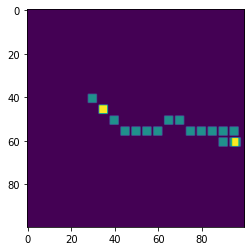

In [43]:
plt.imshow(lap_regions_uav[5])

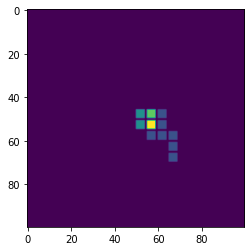

In [44]:
plt.imshow(lap_regions_ugv[5])

In [45]:
overlap = lap_regions_ugv[5] * lap_regions_uav[5]
union = lap_regions_ugv[5] + lap_regions_uav[5]
unique = np.count_nonzero(union) - np.count_nonzero(overlap)
ucr = unique/np.count_nonzero(union)
ucr

0.9493975903614458

In [17]:
overlap = lap_regions_uav[10] * lap_regions_ugv[10]
union = lap_regions_uav[10] + lap_regions_ugv[10]
IOU = overlap.sum()/float(union.sum())
print(IOU)

0.0


## Compute Jensen-Shannon Divergence

In [19]:
from scipy.spatial.distance import jensenshannon

def normalize_map(visitation_map):
    flat = visitation_map.flatten().astype(np.float64)
    total = np.sum(flat)
    return flat / total if total > 0 else flat

def compute_jsd(visitation_maps):
    """
    Compute average Jensen-Shannon Divergence among all pairs of agents.
    
    visitation_maps: list of 2D numpy arrays (one per agent).
    Returns: average JSD score (float)
    """
    num_agents = len(visitation_maps)
    norm_distributions = [normalize_map(vm) for vm in visitation_maps]
    
    jsd_scores = []
    for i in range(num_agents):
        for j in range(i + 1, num_agents):
            jsd = jensenshannon(norm_distributions[i], norm_distributions[j]) ** 2  # JSD is sqrt of divergence
            jsd_scores.append(jsd)

    return np.mean(jsd_scores) if jsd_scores else 0.0

In [22]:
jsd = 0
for i,j in zip(lap_regions_uav, lap_regions_ugv): 
    visitation_maps = [i, j]
    jsd_score = compute_jsd(visitation_maps)
    jsd+=jsd_score
print(f"Average JSD among agents: {jsd/len(lap_regions_uav):.4f}")

Average JSD among agents: 0.6745


## Computing the IOU to make sure the agents are exploring unique regions 

In [10]:
IOU = 0
for i,j in zip(lap_regions_uav, lap_regions_ugv):  
    overlap = i * j
    union = i + j
    IOU += overlap.sum()/float(union.sum())
print(IOU/len(lap_regions_uav))

0.1342479162805984


In [35]:
obs = env.reset()
env.agents['uav'].get_position()

(77, 48)

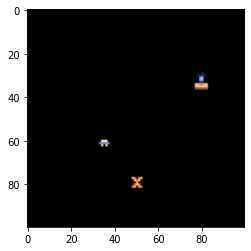

In [36]:
plt.imshow(obs)

In [29]:
random.randrange(20,80)

44

In [18]:
# Using globals() to create a global variable
variable_name = "conv7"
variable_value = 99
globals()[variable_name] = variable_value
 
# Accessing the global variable
retrieved_value = globals()[variable_name]
print(f"{variable_name}: {retrieved_value}")

conv7: 99


In [20]:
conv7

99

## Benchmark

In [ ]:
## Distributed Learning
## Each agent learns end-to-end

## UAV agent is already trained end-to-end since it is the anchor agent
## The UGV agent will be trained end-to-end now

